### Antenna dataset creation

In [ ]:
import os
import glob
import urllib.request
import pandas as pd
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

# --- CONFIGURATION ---
# Points to your raw data directory
DATA_DIR = "../data/antenna_raw_data"
# We can output the images and consolidated CSV in the parent 'data' folder
PARENT_DATA_DIR = os.path.dirname(DATA_DIR)
IMAGES_OUT_DIR = os.path.join(PARENT_DATA_DIR, "antenna_field_images")
CONSOLIDATED_CSV = os.path.join(PARENT_DATA_DIR, "antenna_processed_dataset.csv")

# Create output directories if they don't exist
os.makedirs(IMAGES_OUT_DIR, exist_ok=True)

# 1. Dynamically scan the folder for ALL CSV files
csv_pattern = os.path.join(DATA_DIR, "*.csv")
csv_files = glob.glob(csv_pattern)

# Prevent loading our own output tracking CSV if it's placed in the same folder
csv_files = [f for f in csv_files if os.path.abspath(f) != os.path.abspath(CONSOLIDATED_CSV)]

print(f"🔍 Scanning directory: {DATA_DIR}")
if not csv_files:
    raise FileNotFoundError(f"❌ No CSV files found in {DATA_DIR}. Please check the folder path!")
else:
    print(f"✔ Found {len(csv_files)} CSV files to process:")
    for f in csv_files:
        print(f"  - {os.path.basename(f)}")

# 2. Combine and read all discovered CSV files
df_list = []
for file in csv_files:
    try:
        # FIXED: Use encoding_errors='ignore' to handle encoding anomalies safely
        df_temp = pd.read_csv(file, encoding="utf-8", encoding_errors="ignore")
        df_list.append(df_temp)
    except Exception as e:
        print(f"❌ Error reading {os.path.basename(file)}: {e}")

if not df_list:
    raise ValueError("No data could be loaded from the CSV files.")

df_all = pd.concat(df_list, ignore_index=True)
print(f"\nMerged database shape: {len(df_all)} total raw rows across all files.")

# 3. Filter Records (Keep high-confidence biological observations)
exclude_classes = ["Not Lepidoptera", "Not Identifiable", "Unknown", "Not_Lepidoptera"]
df_filtered = df_all[
    (df_all["verification_status"].isin([True, "Verified"])) & 
    (~df_all["determination_name"].isin(exclude_classes)) &
    (df_all["best_detection_url"].notna())
].copy()

print(f"Filtered down to {len(df_filtered)} high-confidence insect observations.")

# 4. Extract target columns
df_extracted = pd.DataFrame({
    'individual_id': df_filtered['id'],
    'species': df_filtered['determination_name'],
    'location': df_filtered['deployment_name'],
    'pixel_width': df_filtered['best_detection_width'],
    'pixel_height': df_filtered['best_detection_height'],
    'image_url': df_filtered['best_detection_url']
}).drop_duplicates(subset=['individual_id'])

# Create local relative file paths for each downloaded image
df_extracted['local_image_path'] = df_extracted.apply(
    lambda row: os.path.join("antenna_field_images", f"ind_{int(row['individual_id'])}.jpg"), axis=1
)

# 5. Downloader Function
def download_image(row):
    url = row['image_url']
    dest = os.path.join(PARENT_DATA_DIR, row['local_image_path'])
    
    # Avoid duplicate downloads if we re-run the script
    if os.path.exists(dest):
        return True
        
    try:
        # Simple User-Agent header so the cloud server allows the script to fetch the file
        req = urllib.request.Request(
            url, 
            headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
        )
        with urllib.request.urlopen(req, timeout=10) as response, open(dest, 'wb') as out_file:
            out_file.write(response.read())
        return True
    except Exception as e:
        return f"Error downloading ID {row['individual_id']}: {e}"

# 6. Run Batch Download in Parallel Threads
print(f"\n🚀 Downloading {len(df_extracted)} insect crop images to '{IMAGES_OUT_DIR}'...")
records_dict = df_extracted.to_dict(orient='records')

results = []
with ThreadPoolExecutor(max_workers=8) as executor:
    results = list(tqdm(executor.map(download_image, records_dict), total=len(records_dict)))

failed_downloads = [r for r in results if r is not True]
print(f"\n✨ Download sequence finished.")
print(f"  - Successfully verified/downloaded: {len(records_dict) - len(failed_downloads)} crops")
if failed_downloads:
    print(f"  - Failed downloads: {len(failed_downloads)} (These URLs might be offline/slow)")

# 7. Save our clean database to disk
df_extracted.to_csv(CONSOLIDATED_CSV, index=False)
print(f"✔ Saved processed dataset tracking index to: {CONSOLIDATED_CSV}")

🔍 Scanning directory: /home/alexis/Documents/projets/antenna/data/antenna_raw_data
✔ Found 3 CSV files to process:
  - barro-colorado-island-research-station_export-97.csv
  - insectarium-de-montreal_export-103.csv
  - insectarium-de-montreal_export-72.csv

Merged database shape: 10860 total raw rows across all files.
Filtered down to 5747 high-confidence insect observations.

🚀 Downloading 5747 insect crop images to '/home/alexis/Documents/projets/antenna/data/antenna_field_images'...


100%|██████████| 5747/5747 [04:50<00:00, 19.80it/s] 


✨ Download sequence finished.
  - Successfully verified/downloaded: 5747 crops
✔ Saved processed dataset tracking index to: /home/alexis/Documents/projets/antenna/data/antenna_processed_dataset.csv


### Refine Active Backlog: Target Missing Species-Location Samples

In [66]:
import glob
import os
import shutil
import pandas as pd

# ==========================================
# CONFIGURATION
# ==========================================
CSV_PATH = "../data/antenna_processed_dataset.csv"
IMAGES_DIR = "../data/antenna_field_images"
ACTIVE_SET_DIR = "../data/active_annotation_set"

TOP_SPECIES = ["Eulepte", "Perigramma vicina", "Megalopyge albicollis"]
ANNOTATION_TARGET = 10  # Target threshold for completion
BUFFER_PER_SPECIES = 20  # Max candidate images to load per target species

# Safety check
if os.path.abspath(ACTIVE_SET_DIR) == os.path.abspath(IMAGES_DIR):
    raise ValueError(
        "ACTIVE_SET_DIR cannot be the same as IMAGES_DIR to avoid accidental deletion."
    )

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(f"❌ Processed dataset CSV not found at: {CSV_PATH}")

# ==========================================
# 1. LOAD DATA & EXISTING ANNOTATIONS
# ==========================================
df = pd.read_csv(CSV_PATH)

# Identify individual_ids already annotated in IMAGES_DIR
existing_json_files = glob.glob(os.path.join(IMAGES_DIR, "*.json"))
annotated_ids = set()

for f in existing_json_files:
    try:
        parts = os.path.basename(f).replace(".json", "").split("_")
        if len(parts) > 1:
            annotated_ids.add(int(parts[1]))
    except ValueError:
        continue

df["is_annotated"] = df["individual_id"].isin(annotated_ids)

# Generate baseline species summary
species_summary = (
    df.groupby("species")
    .agg(total=("individual_id", "count"), annotated=("is_annotated", "sum"))
    .assign(not_annotated=lambda x: x["total"] - x["annotated"])
    .reset_index()
)

# Species targeted for annotation (< ANNOTATION_TARGET and in TOP_SPECIES or sufficient pool)
species_filtered = species_summary[
    (species_summary["annotated"] < ANNOTATION_TARGET)
    & (species_summary["not_annotated"] > BUFFER_PER_SPECIES)
]
target_species = set(species_filtered["species"].values)

# ==========================================
# 2. CHECK & SYNC ACTIVE_SET_DIR (IF PRESENT)
# ==========================================
if os.path.exists(ACTIVE_SET_DIR):
    active_json_files = glob.glob(
        os.path.join(ACTIVE_SET_DIR, "**", "*.json"), recursive=True
    )
    print("=" * 75)
    print(
        f"🔍 Checking {len(active_json_files)} active annotations in workspace..."
    )

    active_annotations_by_sp = {}

    for f in active_json_files:
        base_name = os.path.basename(f)
        try:
            ind_id = int(base_name.replace(".json", "").split("_")[1])
        except (IndexError, ValueError):
            continue

        match = df[df["individual_id"] == ind_id]
        if match.empty:
            print(
                f"⚠ Warning: {base_name} does not match any known individual_id. Archiving to IMAGES_DIR."
            )
            shutil.copy2(f, os.path.join(IMAGES_DIR, base_name))
        else:
            sp = match["species"].iloc[0]
            active_annotations_by_sp.setdefault(sp, []).append((ind_id, f))

    # Evaluate completion status against target threshold
    completed_any = False
    for sp in target_species:
        prev_count = species_summary.loc[
            species_summary["species"] == sp, "annotated"
        ].iloc[0]
        new_annotations = active_annotations_by_sp.get(sp, [])
        total_now = prev_count + len(new_annotations)

        if total_now >= ANNOTATION_TARGET:
            completed_any = True
            print(
                f"🎉 Target Reached: '{sp}' completed with {total_now}/{ANNOTATION_TARGET} annotations."
            )
            print(
                f"   📦 Syncing files for '{sp}' from ACTIVE_SET_DIR to IMAGES_DIR..."
            )

            for ind_id, json_path in new_annotations:
                # Copy JSON
                shutil.copy2(
                    json_path,
                    os.path.join(IMAGES_DIR, os.path.basename(json_path)),
                )

                # Find and copy corresponding image (jpg, png)
                img_dir = os.path.dirname(json_path)
                matching_imgs = glob.glob(
                    os.path.join(img_dir, f"*{ind_id}*.[jJ][pP][gG]")
                ) + glob.glob(os.path.join(img_dir, f"*{ind_id}*.[pP][nN][gG]"))

                for img_path in matching_imgs:
                    shutil.copy2(
                        img_path,
                        os.path.join(IMAGES_DIR, os.path.basename(img_path)),
                    )

    if not completed_any:
        print(
            f"⏳ Status: No species crossed the >={ANNOTATION_TARGET} threshold yet."
        )
        for sp in target_species:
            prev_count = species_summary.loc[
                species_summary["species"] == sp, "annotated"
            ].iloc[0]
            active_count = len(active_annotations_by_sp.get(sp, []))
            print(
                f"   • {sp}: {prev_count + active_count}/{ANNOTATION_TARGET} annotations completed ({active_count} in current batch)"
            )

    # Clean previous workspace
    shutil.rmtree(ACTIVE_SET_DIR)

# ==========================================
# 3. REPOPULATE ACTIVE WORKSPACE GROUPED BY SPECIES
# ==========================================
os.makedirs(ACTIVE_SET_DIR, exist_ok=True)

print("=" * 75)
print("🎯 POPULATING FRESH ANNOTATION WORKSPACE")
print("=" * 75)

total_copied = 0

for sp in target_species:
    safe_sp = sp.replace(" ", "_").replace("/", "_")
    sp_dir = os.path.join(ACTIVE_SET_DIR, safe_sp)
    os.makedirs(sp_dir, exist_ok=True)

    # Grab unannotated candidates for this species up to BUFFER_PER_SPECIES
    candidates = df[(df["species"] == sp) & (~df["is_annotated"])].head(
        BUFFER_PER_SPECIES
    )

    species_copied = 0
    for _, row in candidates.iterrows():
        ind_id = int(row["individual_id"])
        img_name = f"ind_{ind_id}.jpg"
        src_img_path = os.path.join(IMAGES_DIR, img_name)
        dest_img_path = os.path.join(sp_dir, img_name)

        if os.path.exists(src_img_path):
            shutil.copy2(src_img_path, dest_img_path)
            species_copied += 1

    total_copied += species_copied
    print(
        f"📁 Staged {species_copied} unannotated images for '{sp}' in `{safe_sp}/`"
    )

print(
    f"\n✅ Ready for annotation: {total_copied} total candidate images staged in {ACTIVE_SET_DIR}"
)

🔍 Checking 0 active annotations in workspace...
⏳ Status: No species crossed the >=10 threshold yet.
   • Opisthoxia formosante: 5/10 annotations completed (0 in current batch)
   • Choristoneura fumiferana: 0/10 annotations completed (0 in current batch)
   • Campaea perlata: 9/10 annotations completed (0 in current batch)
   • Spilomela discordens: 1/10 annotations completed (0 in current batch)
   • Perola sericea: 5/10 annotations completed (0 in current batch)
   • Gaudeator paidicus: 3/10 annotations completed (0 in current batch)
   • Megalopyge: 1/10 annotations completed (0 in current batch)
   • Megalopyge tharops: 5/10 annotations completed (0 in current batch)
   • Perigramma guatemalaria: 3/10 annotations completed (0 in current batch)
   • Eacles imperialis: 4/10 annotations completed (0 in current batch)
   • Hygrochroa: 0/10 annotations completed (0 in current batch)
   • Perigramma repetita: 8/10 annotations completed (0 in current batch)
   • Ategumia dilecticolor: 5/

### Annotation stats

This shows a exemple of a mask we created

✔ Found 217 completed annotations.

Image: ind_444097.jpg
Dimensions: 307x256 pixels
Contains 4 segmented shapes:
  Shape 1: Label='full-body' | Type='polygon' | Vertices=105
  Shape 2: Label='head' | Type='polygon' | Vertices=79
  Shape 3: Label='leg' | Type='polygon' | Vertices=125
  Shape 4: Label='leg' | Type='polygon' | Vertices=81


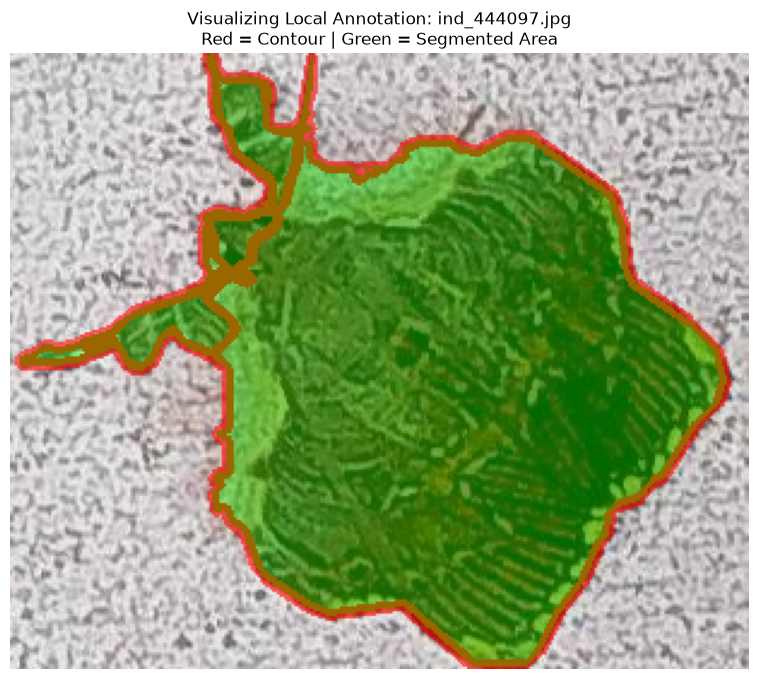

In [2]:
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --- CONFIGURATION ---
DATA_DIR = "../data"
IMAGES_DIR = os.path.join(DATA_DIR, "antenna_field_images")

# 1. Grab all labeled JSON files in your directory
json_files = [f for f in os.listdir(IMAGES_DIR) if f.endswith('.json')]

if not json_files:
    print("⚠ No annotated JSON files found yet. Make sure you saved at least one image in X-AnyLabeling!")
else:
    print(f"✔ Found {len(json_files)} completed annotations.")
    
    # Let's read the very first annotated image
    sample_json_name = json_files[0]
    json_path = os.path.join(IMAGES_DIR, sample_json_name)
    
    # 2. Load and parse the JSON file
    with open(json_path, 'r', encoding='utf-8') as f:
        annotation_data = json.load(f)
        
    # Match the corresponding image filename
    # Typically, the JSON has an "imagePath" key, or we just change the extension of our JSON file
    image_name = annotation_data.get("imagePath", sample_json_name.replace(".json", ".jpg"))
    img_path = os.path.join(IMAGES_DIR, image_name)
    
    # Load the image using OpenCV
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        # Fallback check if it was saved with a different extension
        img_path_fallback = os.path.join(IMAGES_DIR, sample_json_name.replace(".json", ".png"))
        img_bgr = cv2.imread(img_path_fallback)
        
    if img_bgr is None:
         raise FileNotFoundError(f"Could not load matching image for {sample_json_name}")
         
    # Convert to RGB for Matplotlib visualization
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    overlay = img_rgb.copy()
    
    # 3. Parse and draw every shape (polygon) found in the JSON
    shapes = annotation_data.get("shapes", [])
    print(f"\nImage: {image_name}")
    print(f"Dimensions: {annotation_data.get('imageWidth')}x{annotation_data.get('imageHeight')} pixels")
    print(f"Contains {len(shapes)} segmented shapes:")
    
    for i, shape in enumerate(shapes):
        label = shape.get("label", "unknown")
        points = shape.get("points", []) # List of [x, y] coordinates
        shape_type = shape.get("shape_type", "polygon")
        
        print(f"  Shape {i+1}: Label='{label}' | Type='{shape_type}' | Vertices={len(points)}")
        
        # Convert list of coordinate pairs to a NumPy array of integers
        pts = np.array(points, dtype=np.int32)
        
        if shape_type == "polygon":
            # Draw a semi-transparent solid fill inside the polygon
            cv2.fillPoly(overlay, [pts], color=(0, 255, 0)) # Translucent Green
            # Draw a solid outer contour line
            cv2.polylines(img_rgb, [pts], isClosed=True, color=(255, 0, 0), thickness=3) # Bright Red border
            
        elif shape_type == "rectangle":
            # If a simple bounding box was drawn
            pt1, pt2 = pts[0], pts[1]
            cv2.rectangle(img_rgb, tuple(pt1), tuple(pt2), color=(0, 0, 255), thickness=3)
            
    # Blend the original image with the semi-transparent mask fill (alpha blending)
    alpha = 0.4
    final_img = cv2.addWeighted(overlay, alpha, img_rgb, 1 - alpha, 0)
    
    # 4. Plot the final image in your notebook
    plt.figure(figsize=(10, 8))
    plt.imshow(final_img)
    plt.title(f"Visualizing Local Annotation: {image_name}\nRed = Contour | Green = Segmented Area")
    plt.axis("off")
    plt.show()

This snippet is for checking how many of each label categories we have tagged already.

In [21]:
import os
import json
from collections import Counter
import pandas as pd

# --- CONFIGURATION ---
DATA_DIR = "/home/alexis/Documents/projets/antenna/data"
IMAGES_DIR = os.path.join(DATA_DIR, "antenna_field_images")

# 1. Gather all JSON files
json_files = [f for f in os.listdir(IMAGES_DIR) if f.endswith('.json')]

if not json_files:
    print("⚠ No annotated JSON files found. Double-check your path!")
else:
    print(f"📊 Analyzing {len(json_files)} JSON annotations...")
    
    all_labels = []
    file_summary = []
    
    # 2. Parse each JSON file to extract labels and shapes
    for file_name in json_files:
        path = os.path.join(IMAGES_DIR, file_name)
        with open(path, 'r', encoding='utf-8') as f:
            try:
                data = json.load(f)
            except Exception as e:
                print(f"❌ Error reading {file_name}: {e}")
                continue
                
        shapes = data.get("shapes", [])
        labels_in_file = [shape.get("label") for shape in shapes]
        all_labels.extend(labels_in_file)
        
        # Keep track of what each file contains
        file_summary.append({
            "filename": file_name,
            "shape_count": len(shapes),
            "labels": list(set(labels_in_file))
        })

    # 3. Print overall class distribution
    print("\n" + "="*40)
    print("      🏷️  OVERALL LABEL DISTRIBUTION")
    print("="*40)
    label_counts = Counter(all_labels)
    for label, count in label_counts.items():
        print(f"  • {label:<15} : {count} instances")
    print("="*40)
    
    # 4. Turn summary into a clean Pandas DataFrame for deeper check
    df_summary = pd.DataFrame(file_summary)
    
    # Let's see what combinations of labels you have tagged per image
    df_summary['labels_str'] = df_summary['labels'].apply(lambda x: ", ".join(sorted(x)) if x else "[EMPTY]")
    combination_counts = df_summary['labels_str'].value_counts()
    
    print("\n" + "="*40)
    print("   🧩 ANATOMICAL COMBINATIONS PER IMAGE")
    print("="*40)
    for combo, count in combination_counts.items():
        print(f"  • {count:<4} images contain: {combo}")
    print("="*40)

📊 Analyzing 197 JSON annotations...

      🏷️  OVERALL LABEL DISTRIBUTION
  • full-body       : 181 instances
  • head            : 61 instances
  • leg             : 113 instances
  • antenna         : 63 instances
  • wing            : 119 instances
  • body            : 48 instances
  • abdomen         : 5 instances
  • torso           : 3 instances

   🧩 ANATOMICAL COMBINATIONS PER IMAGE
  • 123  images contain: full-body
  • 12   images contain: antenna, body, full-body, head, leg, wing
  • 7    images contain: body, full-body, head, leg, wing
  • 7    images contain: antenna, body, head, leg, wing
  • 5    images contain: body, full-body, head, wing
  • 5    images contain: antenna, body, head, wing
  • 4    images contain: [EMPTY]
  • 4    images contain: body, head, leg, wing
  • 3    images contain: full-body, leg
  • 3    images contain: body, head, wing
  • 3    images contain: full-body, head, wing
  • 2    images contain: full-body, head, leg, wing
  • 1    images contain:

### Species Annotation Status Tracker
Identify which species have annotations, and which ones still need to be annotated.

In [17]:
import os
import json
import pandas as pd

# Load the processed dataset CSV
CSV_PATH = "../data/antenna_processed_dataset.csv"
IMAGES_DIR = "../data/antenna_field_images"

if not os.path.exists(CSV_PATH):
    print("❌ Processed dataset CSV not found!")
else:
    df = pd.read_csv(CSV_PATH)
    
    # Find all annotated JSON files and extract the individual IDs
    json_files = [f for f in os.listdir(IMAGES_DIR) if f.endswith('.json')]
    annotated_ids = set()
    for f in json_files:
        try:
            # Extract ID from filename (e.g. ind_10072.json -> 10072)
            parts = f.replace('.json', '').split('_')
            if len(parts) > 1:
                annotated_ids.add(int(parts[1]))
        except ValueError:
            continue
            
    # Mark which rows in the dataset are annotated
    df['is_annotated'] = df['individual_id'].isin(annotated_ids)
    
    # Compute statistics
    total_species = df['species'].nunique()
    annotated_species_list = df[df['is_annotated']]['species'].unique()
    annotated_species_count = len(annotated_species_list)
    unannotated_species_count = total_species - annotated_species_count
    
    print("="*50)
    print(f"📊 SPECIES ANNOTATION METRICS")
    print("="*50)
    print(f"Total unique species in dataset : {total_species}")
    print(f"Species with at least 1 label   : {annotated_species_count} ({annotated_species_count/total_species*100:.1f}%)")
    print(f"Species with 0 labels           : {unannotated_species_count} ({unannotated_species_count/total_species*100:.1f}%)")
    print("="*50)
    
    # Calculate counts per species for unannotated images
    df_unannotated = df[~df['is_annotated']]
    unannotated_counts = df_unannotated['species'].value_counts()
    
    print(f"\n🔍 TOP SPECIES LACKING LABELS (Work backlog):")
    print("-"*50)
    print(f"{'Species Name':<35} | {'Available Images':<15}")
    print("-"*50)
    for sp, count in unannotated_counts.head(20).items():
        print(f"{sp:<35} | {count:<15}")
    print("-"*50)
    if len(unannotated_counts) > 20:
        print(f"... and {len(unannotated_counts) - 20} more unannotated species.")


📊 SPECIES ANNOTATION METRICS
Total unique species in dataset : 231
Species with at least 1 label   : 56 (24.2%)
Species with 0 labels           : 175 (75.8%)

🔍 TOP SPECIES LACKING LABELS (Work backlog):
--------------------------------------------------
Species Name                        | Available Images
--------------------------------------------------
Eulepte                             | 732            
Perigramma vicina                   | 728            
Megalopyge albicollis               | 474            
Sosxetra grata                      | 367            
Spilomelinae                        | 334            
Lepidoptera                         | 305            
Ategumia dilecticolor               | 272            
Megalopyge tharops                  | 231            
Gaudeator paidicus                  | 209            
Perola sericea                      | 200            
Spilomela perspicata                | 171            
Eacles imperialis                   | 154    

In [20]:
!python ../annotation_backlog.py

🎯 POPULATING ACTIVE ANNOTATION SET
Destination: /home/alexis/Documents/projets/antenna/data/active_annotation_set
✔ Copied 891 images and 197 existing JSON annotations.
👉 Now you can run: xanylabeling
👉 In X-AnyLabeling, open the directory: '/home/alexis/Documents/projets/antenna/data/active_annotation_set' to begin annotating.


### Top 3 Most Annotated Species: Trait Area & Trend Analysis
This cell extracts the polygon areas of manually annotated traits (`full-body`, `wing`, `body`, `antenna`, `leg`, `head`) using the Shoelace formula, identifies the top 3 most annotated species, and prints the average pixel areas and ratios to check for biological scaling trends.

In [1]:
import os
import glob
import json
import numpy as np
import pandas as pd

def shoelace_area(pts):
    if len(pts) < 3:
        return 0
    x = [p[0] for p in pts]
    y = [p[1] for p in pts]
    return 0.5 * np.abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))

CSV_PATH = "../data/antenna_processed_dataset.csv"
IMAGES_DIR = "../data/antenna_field_images"

if not os.path.exists(CSV_PATH):
    print("❌ Processed dataset CSV not found!")
else:
    df = pd.read_csv(CSV_PATH)
    
    # 1. Parse JSON files to calculate trait areas
    records = []
    json_files = glob.glob(os.path.join(IMAGES_DIR, "*.json"))
    
    for f in json_files:
        try:
            ind_id = int(os.path.basename(f).replace('.json', '').split('_')[1])
            sp_rows = df[df['individual_id'] == ind_id]
            if sp_rows.empty:
                continue
            species = sp_rows.iloc[0]['species']
            
            with open(f, 'r', encoding='utf-8') as jf:
                data_json = json.load(jf)
                
            for shape in data_json.get('shapes', []):
                label = shape.get('label')
                points = shape.get('points', [])
                area = shoelace_area(points)
                if area > 0:
                    records.append({
                        'species': species,
                        'label': label,
                        'area_px': area
                    })
        except Exception as e:
            continue
            
    if not records:
        print("⚠ No traits extracted from JSON files.")
    else:
        df_traits = pd.DataFrame(records)
        
        # 2. Find top 3 species with most annotated files
        # Count unique individual_ids per species by scanning the json file names
        annotated_species = []
        for f in json_files:
            try:
                ind_id = int(os.path.basename(f).replace('.json', '').split('_')[1])
                sp = df[df['individual_id'] == ind_id].iloc[0]['species']
                annotated_species.append(sp)
            except:
                continue
        
        top_species = pd.Series(annotated_species).value_counts().head(3).index.tolist()
        
        print("="*65)
        print(f"📈 TRAIT ANALYSIS FOR TOP 3 SPECIES: {', '.join(top_species)}")
        print("="*65)
        
        for sp in top_species:
            df_sp = df_traits[df_traits['species'] == sp]
            print(f"\nSpecies: {sp}")
            print("-"*65)
            
            # Group and get average area
            summary = df_sp.groupby('label')['area_px'].agg(['count', 'mean']).reset_index()
            print(summary.to_string(index=False, formatters={'mean': '{:,.1f} px'.format}))
            
            # Compute interesting biological ratios
            means = df_sp.groupby('label')['area_px'].mean().to_dict()
            if 'wing' in means and 'full-body' in means:
                ratio = (means['wing'] / means['full-body']) * 100
                print(f"  • Wing-to-Body Area Ratio    : {ratio:.2f}%")
            if 'antenna' in means and 'full-body' in means:
                ratio = (means['antenna'] / means['full-body']) * 100
                print(f"  • Antenna-to-Body Area Ratio : {ratio:.2f}%")
            print("-"*65)


📈 TRAIT ANALYSIS FOR TOP 3 SPECIES: Eulepte, Perigramma vicina, Megalopyge albicollis

Species: Eulepte
-----------------------------------------------------------------
    label  count        mean
  antenna      7    273.2 px
     body     21  2,043.4 px
full-body     34 19,044.4 px
     head     23    322.8 px
      leg     25    211.4 px
     wing     44  9,205.3 px
  • Wing-to-Body Area Ratio    : 48.34%
  • Antenna-to-Body Area Ratio : 1.43%
-----------------------------------------------------------------

Species: Perigramma vicina
-----------------------------------------------------------------
    label  count        mean
  antenna     42    440.7 px
     body     20  3,905.1 px
full-body     22 52,981.0 px
     head     21    449.8 px
      leg     37    389.1 px
     wing     44 24,339.2 px
  • Wing-to-Body Area Ratio    : 45.94%
  • Antenna-to-Body Area Ratio : 0.83%
-----------------------------------------------------------------

Species: Megalopyge albicollis
--------

### Spatial Sizing & Trait Deviation Analysis
This cell checks if the sampling location (deployment name) influences the size of manual traits (`full-body`, `wing`, etc.) for our top species, analyzing deviations from the global species average.

In [ ]:
import os
import glob
import json
import numpy as np
import pandas as pd

def shoelace_area(pts):
    if len(pts) < 3:
        return 0
    x = [p[0] for p in pts]
    y = [p[1] for p in pts]
    return 0.5 * np.abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))

CSV_PATH = "../data/antenna_processed_dataset.csv"
IMAGES_DIR = "../data/antenna_field_images"

if not os.path.exists(CSV_PATH):
    print("❌ Processed dataset CSV not found!")
else:
    df = pd.read_csv(CSV_PATH)
    
    # 1. Parse JSON files
    records = []
    json_files = glob.glob(os.path.join(IMAGES_DIR, "*.json"))
    
    for f in json_files:
        try:
            ind_id = int(os.path.basename(f).replace('.json', '').split('_')[1])
            sp_rows = df[df['individual_id'] == ind_id]
            if sp_rows.empty:
                continue
            species = sp_rows.iloc[0]['species']
            location = sp_rows.iloc[0]['location']
            
            with open(f, 'r', encoding='utf-8') as jf:
                data_json = json.load(jf)
                
            for shape in data_json.get('shapes', []):
                label = shape.get('label')
                points = shape.get('points', [])
                area = shoelace_area(points)
                if area > 0:
                    records.append({
                        'species': species,
                        'location': location,
                        'label': label,
                        'area_px': area
                    })
        except Exception as e:
            continue
            
    if not records:
        print("⚠ No traits extracted from JSON files.")
    else:
        df_traits = pd.DataFrame(records)
        
        # Analyze top 3 species
        annotated_species = []
        for f in json_files:
            try:
                ind_id = int(os.path.basename(f).replace('.json', '').split('_')[1])
                sp = df[df['individual_id'] == ind_id].iloc[0]['species']
                annotated_species.append(sp)
            except:
                continue
        top_species = pd.Series(annotated_species).value_counts().head(3).index.tolist()
        
        print("="*75)
        print(f"🌍 SPATIAL SIZING DEVIATION ANALYSIS (For 'full-body' trait)")
        print("="*75)
        
        for sp in top_species:
            df_sp = df_traits[(df_traits['species'] == sp) & (df_traits['label'] == 'full-body')]
            if df_sp.empty:
                continue
(            global_mean = df_sp['area_px'].mean()
            print(f"\nSpecies: {sp} (Overall Mean: {global_mean:,.1f} px)")
            print("-"*75)
            print(f"{'Location':<30} | {'Count':<6} | {'Mean Area':<15} | {'Deviation %':<12}")
            print("-"*75)
            
            loc_summary = df_sp.groupby('location')['area_px'].agg(['count', 'mean']).reset_index()
            for _, row in loc_summary.iterrows():
                loc = row['location']
                count = row['count']
                loc_mean = row['mean']
                dev = ((loc_mean - global_mean) / global_mean) * 100
                dev_str = f"{dev:+.1f}%"
                print(f"{loc:<30} | {count:<6} | {loc_mean:<15,.1f} | {dev_str:<12}")
            print("-"*75)


### Trait Dimensions (Length/Width) & Multi-Species Location Comparison
This cell measures the physical dimensions (Length and Width) of the traits using the **Minimum Area Rotated Rectangle (OBB)** from OpenCV. It then compares the size deviations of different species at the same location to determine if the variation is due to camera scaling/calibration (where all species scale together) or biological differences (where species scale differently).

In [1]:
import os
import glob
import json
import cv2
import numpy as np
import pandas as pd

def get_obb_dimensions(pts):
    if len(pts) < 3:
        return 0, 0
    pts_arr = np.array(pts, dtype=np.float32).reshape(-1, 1, 2)
    rect = cv2.minAreaRect(pts_arr)
    _, (w, h), _ = rect
    length = max(w, h)
    width = min(w, h)
    return length, width

CSV_PATH = "../data/antenna_processed_dataset.csv"
IMAGES_DIR = "../data/antenna_field_images"
TOP_SPECIES = ['Eulepte', 'Perigramma vicina', 'Megalopyge albicollis']

if not os.path.exists(CSV_PATH):
    print("❌ Processed dataset CSV not found!")
else:
    df = pd.read_csv(CSV_PATH)
    
    # 1. Parse JSON files to calculate length/width
    records = []
    json_files = glob.glob(os.path.join(IMAGES_DIR, "*.json"))
    
    for f in json_files:
        try:
            ind_id = int(os.path.basename(f).replace('.json', '').split('_')[1])
            sp_rows = df[df['individual_id'] == ind_id]
            if sp_rows.empty:
                continue
            species = sp_rows.iloc[0]['species']
            location = sp_rows.iloc[0]['location']
            
            with open(f, 'r', encoding='utf-8') as jf:
                data_json = json.load(jf)
                
            for shape in data_json.get('shapes', []):
                label = shape.get('label')
                points = shape.get('points', [])
                length, width = get_obb_dimensions(points)
                if length > 0:
                    records.append({
                        'species': species,
                        'location': location,
                        'label': label,
                        'length_px': length,
                        'width_px': width
                    })
        except Exception as e:
            continue
            
    if not records:
        print("⚠ No traits extracted from JSON files.")
    else:
        df_traits = pd.DataFrame(records)
        
        # Filter for 'full-body' trait of top species
        df_body = df_traits[(df_traits['species'].isin(TOP_SPECIES)) & (df_traits['label'] == 'full-body')].copy()
        
        # Calculate global species means for normalization
        global_means = df_body.groupby('species')[['length_px', 'width_px']].mean().to_dict()
        
        # Calculate location means per species
        loc_means = df_body.groupby(['location', 'species']).agg(count=('label', 'count'), mean_length=('length_px', 'mean'), mean_width=('width_px', 'mean')).reset_index()
        # Column names are already set by agg()
        
        # Calculate deviation from global species average
        deviations = []
        for _, row in loc_means.iterrows():
            sp = row['species']
            l_glob = global_means['length_px'][sp]
            w_glob = global_means['width_px'][sp]
            
            l_dev = ((row['mean_length'] - l_glob) / l_glob) * 100
            w_dev = ((row['mean_width'] - w_glob) / w_glob) * 100
            
            deviations.append({
                'location': row['location'],
                'species': sp,
                'count': row['count'],
                'length_px': row['mean_length'],
                'width_px': row['mean_width'],
                'length_dev_%': l_dev,
                'width_dev_%': w_dev
            })
            
        df_dev = pd.DataFrame(deviations)
        
        print("="*85)
        print(f"📊 CROSS-LOCATION DEVIATION COMPARISON (Full-body Length/Width in px)")
        print("="*85)
        
        # Group by location to compare different species at the same place
        for loc in df_dev['location'].unique():
            df_loc = df_dev[df_dev['location'] == loc]
            print(f"\n📍 Location: {loc}")
            print("-"*85)
            print(f"{'Species Name':<22} | {'Count':<5} | {'Length (px)':<12} | {'Len Dev %':<10} | {'Width (px)':<12} | {'Wid Dev %':<10}")
            print("-"*85)
            for _, row in df_loc.iterrows():
                print(f"{row['species']:<22} | {int(row['count']):<5} | {row['length_px']:<12.1f} | {row['length_dev_%']:+10.1f}% | {row['width_px']:<12.1f} | {row['width_dev_%']:+10.1f}%")
            print("-"*85)


📊 CROSS-LOCATION DEVIATION COMPARISON (Full-body Length/Width in px)

📍 Location: AMI 2BD0E9C1
-------------------------------------------------------------------------------------
Species Name           | Count | Length (px)  | Len Dev %  | Width (px)   | Wid Dev % 
-------------------------------------------------------------------------------------
Eulepte                | 7     | 278.6        |       +9.0% | 134.6        |      +10.1%
Megalopyge albicollis  | 6     | 226.7        |       -4.3% | 179.9        |       -1.5%
Perigramma vicina      | 5     | 432.4        |       +2.5% | 204.7        |       -0.7%
-------------------------------------------------------------------------------------

📍 Location: AMI BEF510C3
-------------------------------------------------------------------------------------
Species Name           | Count | Length (px)  | Len Dev %  | Width (px)   | Wid Dev % 
-------------------------------------------------------------------------------------
Eulepte 

### Detailed Specific Traits Spatial Comparison
This cell extends the spatial comparison to all individual annotated traits (`wing`, `body`, `antenna`, `leg`, `head`). It prints a comparative breakdown of oriented length and width (in pixels) across locations to identify if specific organs (like antennas or wings) scale differently than the rest of the body.

In [2]:
import os
import glob
import json
import cv2
import numpy as np
import pandas as pd

def get_obb_dimensions(pts):
    if len(pts) < 3:
        return 0, 0
    pts_arr = np.array(pts, dtype=np.float32).reshape(-1, 1, 2)
    rect = cv2.minAreaRect(pts_arr)
    _, (w, h), _ = rect
    return max(w, h), min(w, h)

CSV_PATH = "../data/antenna_processed_dataset.csv"
IMAGES_DIR = "../data/antenna_field_images"
TOP_SPECIES = ['Eulepte', 'Perigramma vicina', 'Megalopyge albicollis']

if not os.path.exists(CSV_PATH):
    print("❌ Processed dataset CSV not found!")
else:
    df = pd.read_csv(CSV_PATH)
    
    # 1. Parse JSON files to calculate length/width for all traits
    records = []
    json_files = glob.glob(os.path.join(IMAGES_DIR, "*.json"))
    
    for f in json_files:
        try:
            ind_id = int(os.path.basename(f).replace('.json', '').split('_')[1])
            sp_rows = df[df['individual_id'] == ind_id]
            if sp_rows.empty:
                continue
            species = sp_rows.iloc[0]['species']
            location = sp_rows.iloc[0]['location']
            
            with open(f, 'r', encoding='utf-8') as jf:
                data_json = json.load(jf)
                
            for shape in data_json.get('shapes', []):
                label = shape.get('label')
                points = shape.get('points', [])
                length, width = get_obb_dimensions(points)
                if length > 0:
                    records.append({
                        'species': species,
                        'location': location,
                        'label': label,
                        'length_px': length,
                        'width_px': width
                    })
        except Exception as e:
            continue
            
    if not records:
        print("⚠ No traits extracted from JSON files.")
    else:
        df_traits = pd.DataFrame(records)
        df_top = df_traits[df_traits['species'].isin(TOP_SPECIES)].copy()
        
        print("="*85)
        print(f"📊 SPECIFIC TRAIT DIMENSION STABILITY COMPARISON")
        print("="*85)
        
        for sp in TOP_SPECIES:
            df_sp = df_top[df_top['species'] == sp]
            if df_sp.empty:
                continue
            
            print(f"\nSpecies: {sp}")
            print("-"*85)
            
            # Pivot table to show trait means across locations
            summary = df_sp.groupby(['location', 'label'])['length_px'].mean().unstack(fill_value=0)
            print(summary.to_string(formatters={c: '{:,.1f} px'.format for c in summary.columns}))
            print("-"*85)


📊 SPECIFIC TRAIT DIMENSION STABILITY COMPARISON

Species: Eulepte
-------------------------------------------------------------------------------------
label                      antenna     body full-body    head     leg     wing
location                                                                      
AMI 2BD0E9C1               90.0 px 122.3 px  278.6 px 24.3 px 45.7 px 142.9 px
AMI BEF510C3               54.7 px 114.0 px  241.7 px 21.9 px 50.4 px 140.3 px
AMI E43B615A               52.6 px 100.3 px  244.5 px 23.5 px  0.0 px 125.4 px
AMI System v2 Sample (Nov)  0.0 px 164.4 px  306.5 px 31.1 px 55.6 px 153.0 px
-------------------------------------------------------------------------------------

Species: Perigramma vicina
-------------------------------------------------------------------------------------
label                       antenna     body full-body    head     leg     wing
location                                                                       
AMI 2BD0E9C1  

### Oriented Bounding Box (OBB) Fitting Visualization
This cell visualizes how the Minimum Area Rotated Bounding Boxes (drawn as white dashed lines) encapsulate your manually drawn polygon contours (colored solid lines) for the different traits.

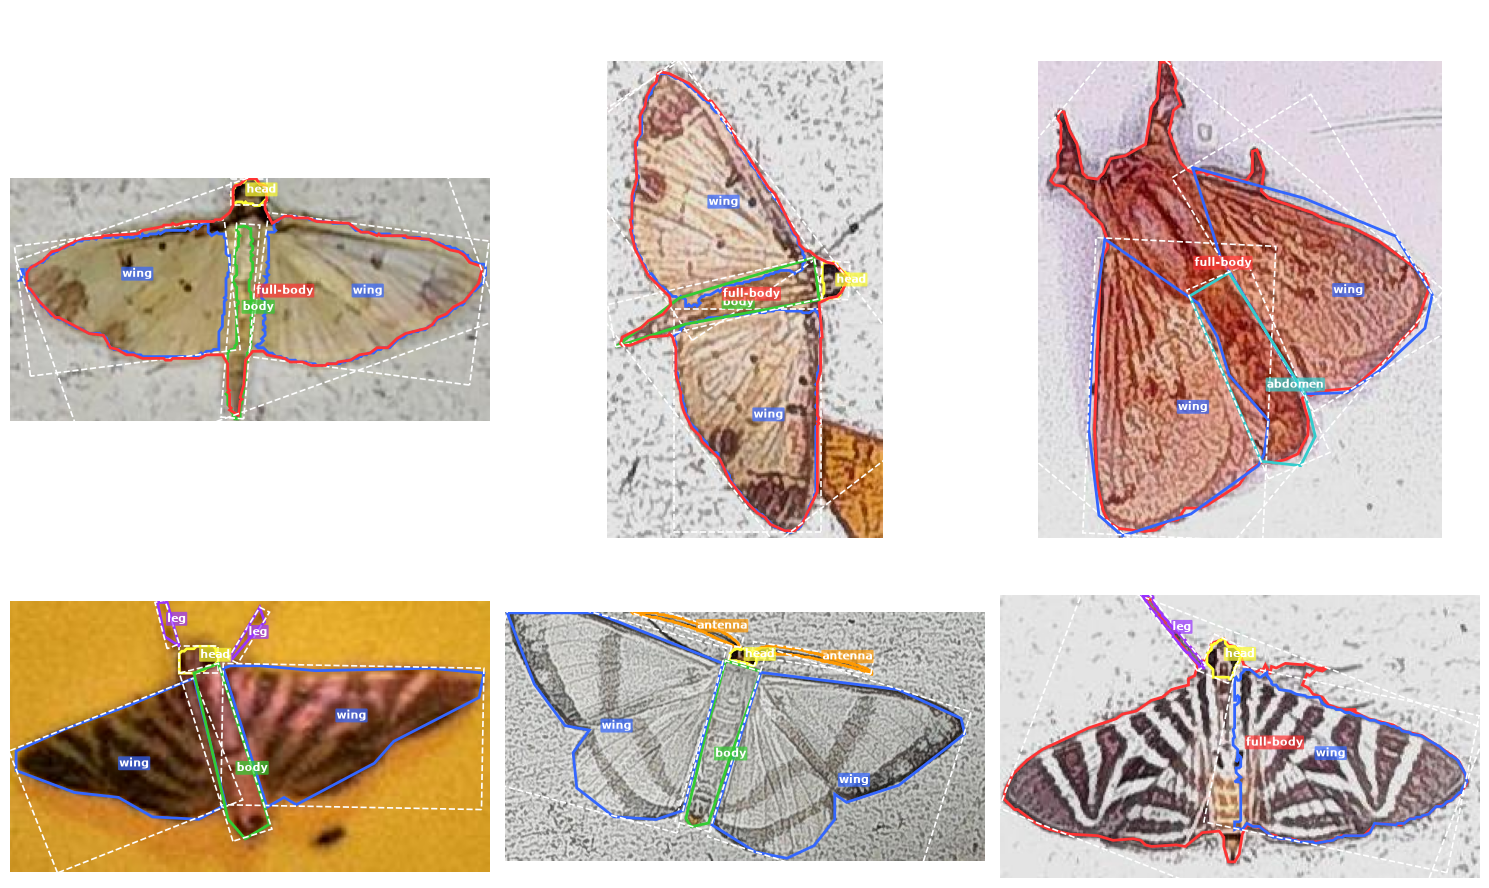

In [38]:
import os
import glob
import json
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt

IMAGES_DIR = "../data/antenna_field_images"

def visualize_single_obb_fitting(json_path, ax):
    # Load image
    img_path = json_path.replace('.json', '.jpg')
    if not os.path.exists(img_path):
        return
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    
    # Load shapes
    with open(json_path, 'r', encoding='utf-8') as jf:
        data_json = json.load(jf)
        
    colors = {
        'full-body': '#FF3333',
        'wing': '#3366FF',
        'body': '#33CC33',
        'antenna': '#FF9900',
        'leg': '#9933FF',
        'head': '#FFFF33'
    }
    
    for shape in data_json.get('shapes', []):
        label = shape.get('label')
        points = np.array(shape.get('points', []), dtype=np.int32)
        color = colors.get(label, '#33CCCC')
        
        # 1. Plot original polygon contour
        poly = plt.Polygon(points, fill=False, edgecolor=color, linewidth=2, label=f"Contour: {label}")
        ax.add_patch(poly)
        
        # 2. Compute and plot Min Area Bounding Box (OBB)
        pts_arr = np.array(points, dtype=np.float32).reshape(-1, 1, 2)
        rect = cv2.minAreaRect(pts_arr)
        box = cv2.boxPoints(rect)
        box = np.intp(box)
        
        obb = plt.Polygon(box, fill=False, edgecolor='#FFFFFF', linestyle='--', linewidth=1.2, label=f"OBB: {label}")
        ax.add_patch(obb)
        
        # Add text label at centroid
        cx, cy = np.mean(points, axis=0)
        ax.text(cx, cy, label, color='white', fontsize=8, weight='bold', 
                 bbox=dict(facecolor=color, alpha=0.7, edgecolor='none', boxstyle='round,pad=0.1'))
        
    ax.set_title(os.path.basename(img_path), fontsize=10, color='white')
    ax.axis('off')

def plot_obb_fitting_samples(num_samples=6):
    json_files = glob.glob(os.path.join(IMAGES_DIR, "*.json"))
    # Filter for files that actually have annotated traits
    valid_files = []
    for f in json_files:
        with open(f, 'r', encoding='utf-8') as jf:
            data_json = json.load(jf)
        if len(data_json.get("shapes", [])) >= 3:
            valid_files.append(f)
            
    if not valid_files:
        print("❌ No annotated files with multiple shapes found.")
        return
        
    samples = random.sample(valid_files, min(num_samples, len(valid_files)))
    
    # Create a grid layout
    cols = 3
    rows = (len(samples) + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
    axes = axes.flatten() if hasattr(axes, 'flatten') else [axes]
    
    for i, json_path in enumerate(samples):
        visualize_single_obb_fitting(json_path, axes[i])
        
    # Turn off unused subplots
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
        
    plt.suptitle("Oriented Bounding Box (OBB) Fitting Grid Check", fontsize=16, color='white')
    plt.tight_layout()
    plt.show()

# Run the visualization for 6 random samples
plot_obb_fitting_samples(num_samples=6)
